# SDY2823有限失败诊断

## tl;dr

2026-10-13，在原96位供者、3个有独立流式标签的问题及冻结模型上完成有界事后诊断，没有增加独立样本、重训或修改既有结果。

原来0.411的单次全基因打乱结果不能代表打乱总体。两类31次技术重复的中位nDCG约为0.240和0.244，原始RNA为0.327；仍有10/31和9/31次达到或超过原始RNA。本队列RNA表示的约98%变化集中在第一主成分，T/B查询得分高度相关。它在旧CPM和恢复归一化下均存在，不是本次修复新造成的现象。

**这些结果没有建立实用检索优势，也没有证明模型全局失效或定位唯一原因。** 原研究门槛仍未通过。

## Context & Methods

PROTOCOL.json在本轮运行前锁定两个打乱定义、20261013–20261043的31个种子、10,000次联合样本标签重排、几何和输入诊断。此前结果已被观察，因此这是事后诊断，不是预注册或确认性检验。

### Key Assumptions

- 全映射基因打乱严格重复原对照定义，保留23,323个值的多重集合，但可能改变投影后特征的值分布。
- 另一个对照仅打乱3,524个实测模型特征，保留它们的值分布；572个缺失位置保持原零输入约定。两种定义不合并为同一个对照。
- 先保存新向量和90个查询的得分，再读取评价标签。每题3个改写先取平均，然后对3题平均；62次控制不是62个独立生物学问题。
- 所有种子和问题保留，不选最好或最坏的结果。只有Q01、Q02、Q19有本轮标签，其余27题没有获得独立有效性验证。
- 样本标签重排对所有方法和查询采用相同的供者置换，保留每位供者的联合等级结构。参考分位数不是跨队列置信区间，参考比例不是一般性优越性P值。

## Data

### 1. 重读与独立核验

input、权重、源代码和查询都由父运行及本轮合同固定。独立核验采用直接DCG求和、scikit-learn、直接重排及Gram矩阵特征值等不同计算路径。

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from verify_diagnostic import verify
out=Path.cwd();study=out.parent
checks=verify(study,out)
assert checks==json.loads((out/'independent_validation.json').read_text())
summary=json.loads((out/'analysis_summary.json').read_text())
assert summary['Linux_Mac_top10_orders_all_equal']
print(f"5,670组新得分重构误差 {checks['max_score_error']}; 567组指标最大误差 {checks['max_metric_error']:.3g}; 540组直接标签重排核验通过。")
print('Linux与Mac原始RNA/原种子对照的18组top-10顺序全部一致；旧源文件未改变。')

5,670组新得分重构误差 0.0; 567组指标最大误差 2.22e-16; 540组直接标签重排核验通过。
Linux与Mac原始RNA/原种子对照的18组top-10顺序全部一致；旧源文件未改变。


## Results

### 2. 打乱结果有较大技术波动

图中显示全部62个技术重复。箱体表示四分位范围，须线表示本轮最小/最大值，不是置信区间。菱形只标出此前已报告的那一个全映射基因打乱种子。

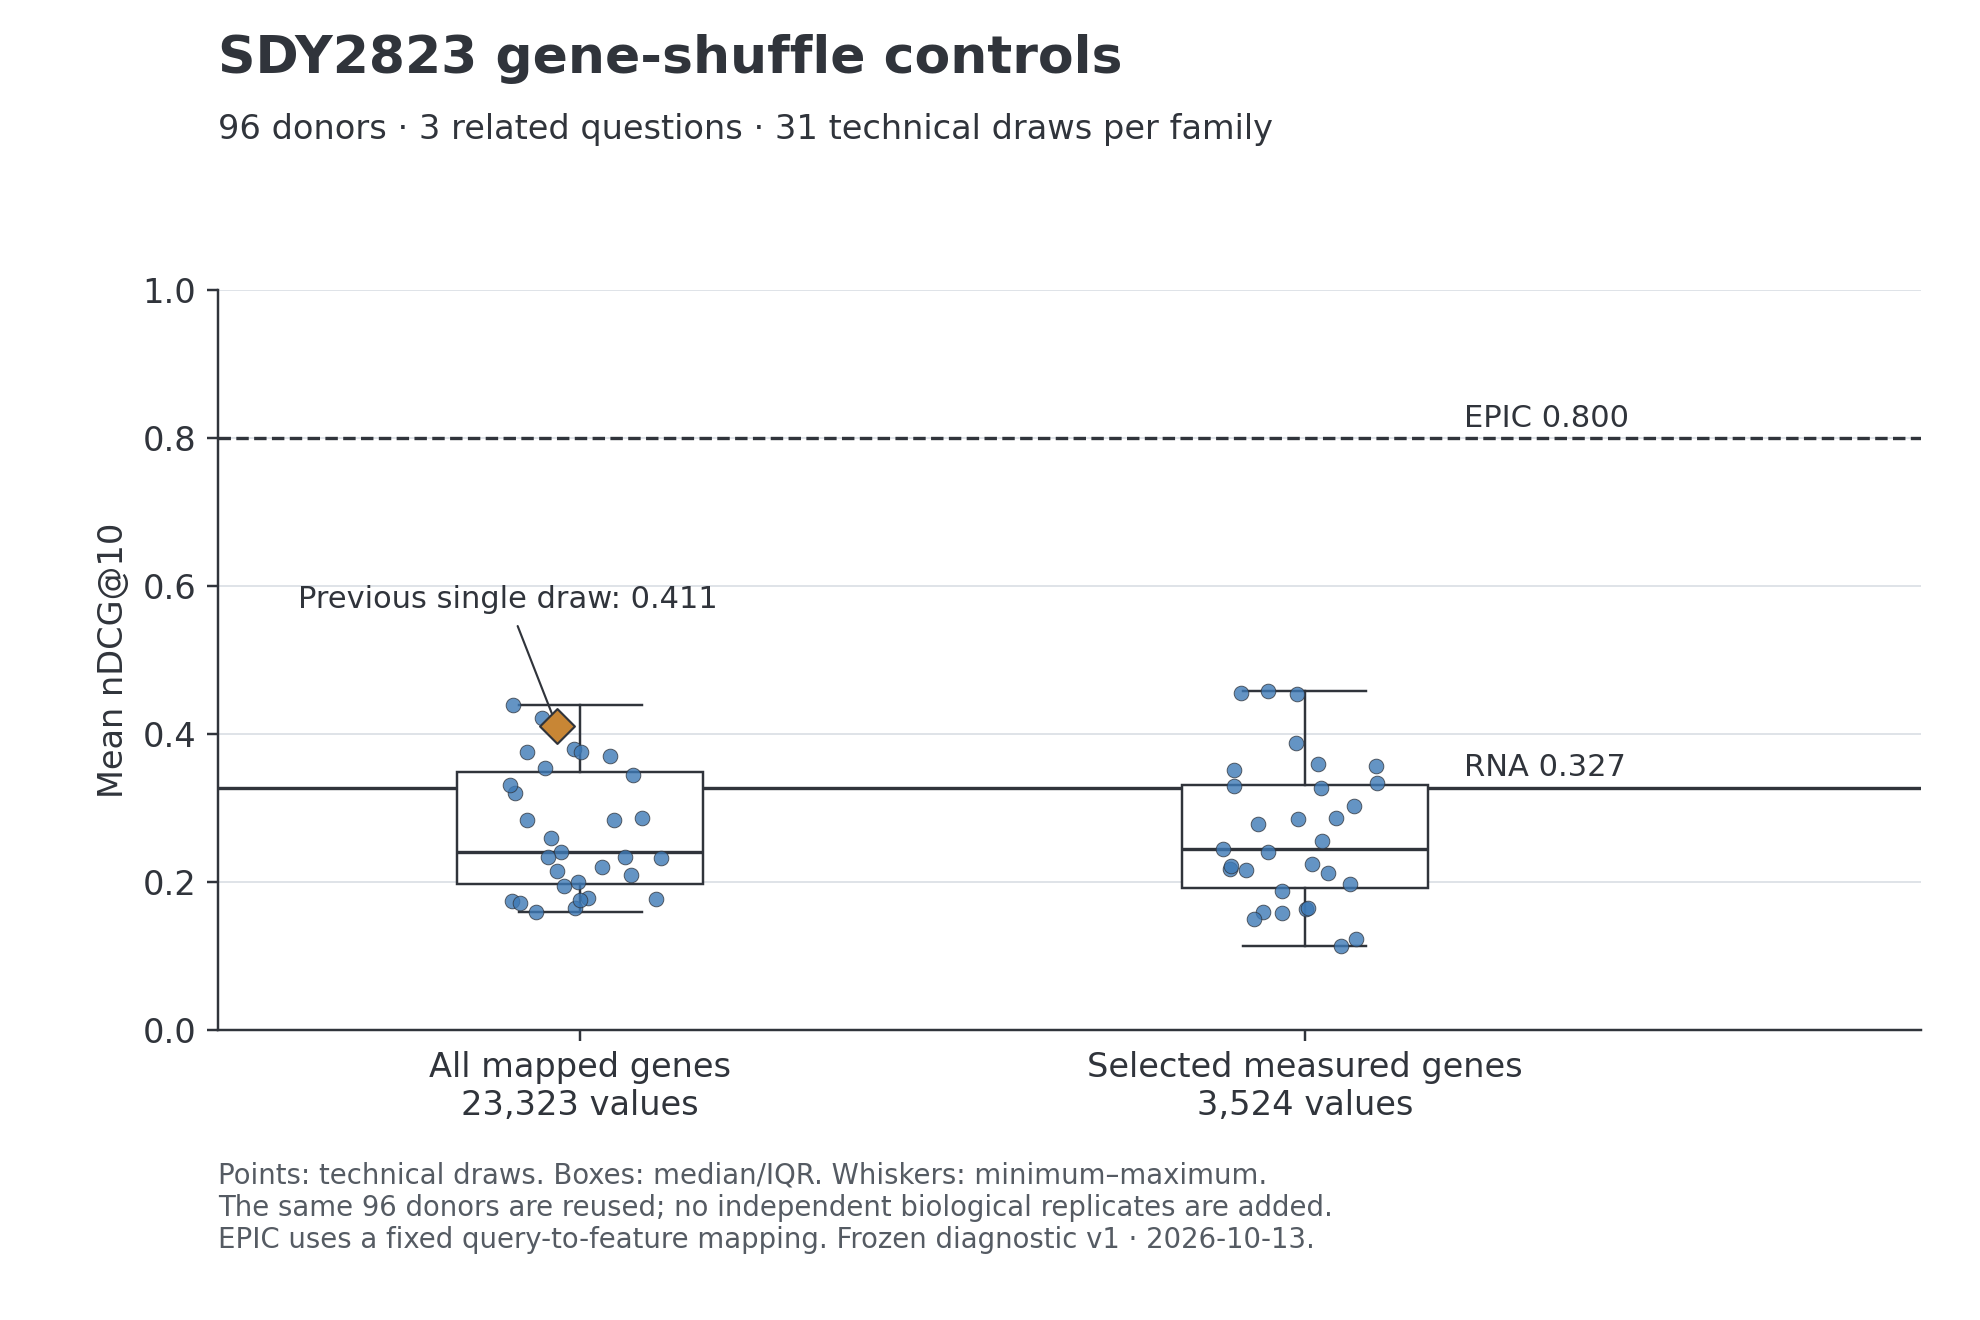

In [2]:
from build_notebook import make_figure
from IPython.display import Image,display
make_figure(out)
display(Image(filename=str(out/'control_distribution.png')))

In [3]:
distribution=pd.read_csv(out/'control_distributions.csv')
distribution[['family','replicates','mean','median','min','max','replicates_at_least_unmodified']].round(3)

,family,replicates,mean,median,min,max,replicates_at_least_unmodified
0,all_mapped,31,0.271,0.240,0.160,0.439,10
1,selected_measured,31,0.265,0.244,0.113,0.458,9


### 3. 随机标签参考不能当作新的生物学证据

固定当前候选池和相关性等级后，随机排序的解析期望为0.292824。原始RNA 0.327位于其条件参考范围内。下表仅列预先关心的代表方法；全部27方法保存在CSV中。比例为这10,000次重排的描述，不报告一般性检验P值；0表示本轮没有出现，不表示概率为0。

In [4]:
reference=pd.read_csv(out/'sample_label_randomization_summary.csv').set_index('method')
selected=['rna_direct_sf_reference','rna_fused_sf_reference','full_portrait_released_calibration_sf_reference','EPIC_BRef_raw']
pd.set_option('display.max_colwidth',None)
reference.loc[selected,['observed_ndcg','analytic_random_mean','reference_p025','reference_p975','fraction_random_assignments_at_least_observed']].round(4)

,observed_ndcg,analytic_random_mean,reference_p025,reference_p975,fraction_random_assignments_at_least_observed
method,,,,,
rna_direct_sf_reference,0.3275,0.2928,0.1722,0.4288,0.2894
rna_fused_sf_reference,0.3729,0.2928,0.1737,0.4311,0.1202
full_portrait_released_calibration_sf_reference,0.2028,0.2928,0.1533,0.4521,0.8770
EPIC_BRef_raw,0.7999,0.2928,0.1219,0.5139,0.0000


### 4. 本队列表示的变化近似一维

这里的参与率维数由中心化表示协方差的特征值计算，不是模型的全局生物学维数。旧CPM和恢复归一化下均约为1.04，第一主成分占约98%。恢复归一化后的样本平均余弦相似度下降，说明输入变化确实影响了表示；不能把它说成所有样本完全相同，也不能仅凭几何确定训练失败原因。

In [5]:
geometry=pd.read_csv(out/'embedding_geometry.csv').set_index('condition')
geometry.loc[['old_CPM_direct','rna_direct_sf_reference'],['pair_cosine_mean','centered_participation_dimension','first_PC_variance_fraction']].round(4)

,pair_cosine_mean,centered_participation_dimension,first_PC_variance_fraction
condition,,,
old_CPM_direct,0.8852,1.0337,0.9836
rna_direct_sf_reference,0.8205,1.0390,0.9810


### 5. T/B查询排序缺少针对性，但不是所有文本查询投影都塌缩

T与B查询的平均得分在本队列中高度相关：直接RNA约0.943，完整portrait约0.984，EPIC约0.395。另一方面，全部30题的改写内与题目质心间余弦均值差，在文本投影后并没有缩小。因此不能将现象简单归结为全部文本查询坍缩。余弦差只作描述性几何量，不是独立语义准确率。

In [6]:
pairs=pd.read_csv(out/'cross_query_score_correlations.csv')
show=pairs.query("query_a=='Q01' and query_b=='Q02'")
show=show.loc[show.method.isin(['rna_direct_sf_reference','full_portrait_released_calibration_sf_reference','EPIC_BRef_raw','cellwhisperer_v1'])]
display(show.round(4))
pd.read_csv(out/'query_geometry_summary.csv').round(4)

,method,query_a,query_b,mean_score_spearman
6,EPIC_BRef_raw,Q01,Q02,0.3948
18,cellwhisperer_v1,Q01,Q02,0.6487
30,full_portrait_released_calibration_sf_reference,Q01,Q02,0.9837
51,rna_direct_sf_reference,Q01,Q02,0.9433


,space,questions,within_paraphrase_mean,between_question_centroid_mean,descriptive_within_minus_between
0,raw_text,30,0.6825,0.5353,0.1472
1,projected_RNA_query,30,0.8216,0.6070,0.2146


原始RNA直接检索在每题三个改写之间的top-10 Jaccard均值约0.179。较高的查询向量余弦相似度并不保证返回相同候选。以下直接重读已冻结的父评价表，不新增问题，也不将传统方法固定查询映射所产生的稳定性当作自然语言理解能力。

In [7]:
parent_means=pd.read_csv(study/'normalization_reassessment_20261013/ssd_rerun_v1/three_question_descriptive_means.csv').set_index('method')
parent_means.loc[['rna_direct_sf_reference','rna_fused_sf_reference','full_portrait_released_calibration_sf_reference','cellwhisperer_v1'],['paraphrase_top10_jaccard']].round(4)

,paraphrase_top10_jaccard
method,
rna_direct_sf_reference,0.1795
rna_fused_sf_reference,0.1609
full_portrait_released_calibration_sf_reference,0.2995
cellwhisperer_v1,0.2610


### 6. 映射成功不等于每个特征都有非零表达

未打乱样本中，已映射模型特征的零值比例中位数约73.9%；这与572个未映射位置是不同问题。两种归一化的这项比例相同。原始输入未出现±8裁切，因此本轮没有支持把现象主要归因于裁切。全映射打乱后的特征零值比例中位数约39.0%，仅实测特征打乱则保留约73.9%。这是设置第二类对照的原因，不能忽略两种干预的区别。两个处理中位表达值为0不意味着全部表达值不变。

In [8]:
inputs=pd.read_csv(out/'control_input_diagnostics.csv')
assert checks['preprocessing_upper_clip_max']==checks['preprocessing_lower_clip_max']==0
inputs.groupby('family')[['zero_fraction_measured','upper_clip_fraction_measured','lower_clip_fraction_measured']].median().round(5)

,zero_fraction_measured,upper_clip_fraction_measured,lower_clip_fraction_measured
family,,,
all_mapped,0.38961,0.0,0.0
selected_measured,0.73879,0.0,0.0
unmodified,0.73879,0.0,0.0


### 7. 预设输入摘要的相关性

表格给出原始RNA得分与五个固定输入摘要的Spearman相关，各题取三个改写的中位数。没有拟合解释模型、选择最有利变量或声称因果。全部27个方法和每种改写的值保存在score_input_correlations.csv；常数变量/得分标为空值，不填0。

In [9]:
associations=pd.read_csv(out/'score_input_correlations.csv')
associations.loc[associations.method.eq('rna_direct_sf_reference')].groupby(['input_summary','query_id']).spearman.median().unstack().round(4)

query_id,Q01,Q02,Q19
input_summary,,,
IQR_log_sf_reference,0.1700,0.2109,0.1813
mapped_count_sum,-0.0377,0.0131,-0.0244
median_log_sf_reference,-0.0826,-0.1098,-0.0654
size_factor,-0.0226,0.0371,-0.0128
zero_fraction_mapped,-0.0717,-0.0869,-0.0663


## Takeaways

- 修正的是对单次打乱结果的解释：0.411不是稳定的打乱优势。原始RNA高于两类控制的中位数，但存在较多重叠，不能据此宣称强表达依赖或实用优势。
- 本血液队列的RNA表示低有效维度、T/B查询得分高度相似，是可追溯的观察，不是模型全局失效的证明；唯一原因尚未定位。
- 传统EPIC在相同三题上的相关性更高，但它使用固定查询—特征映射，不是无限制自然语言解析器。人工映射和核查成本仍未得到量化。
- 当前结果不支持扩大确认性或湿实验投入。还需完成原计划中已有CPTAC候选池的正确尺度复评，保留SDY阴性结果，不以选择数据集或重训来掩盖它。
- 没有新增独立问题/供者、人工语句评分、机制发现或稿件改写。本笔记与图是诊断记录，不替代原计划中的主文科学图件。

可作为有明确边界的事后诊断分享；完整Cell计划尚未完成。